# EDA — Ngành hàng & Sản phẩm 


| # | Câu hỏi |
|---|---|
| 1 | Doanh thu sản phẩm đang ở quy mô nào, năm nay so với năm trước ra sao? |
| 2 | Ngành hàng nào tạo ra doanh thu? Ngành đó bán nhờ số lượng hay nhờ giá? | 
| 3 | Ngành nào là trụ cột, ngành nào đang lên, ngành nào đang đi xuống? | 
| 4 | Cơ cấu ngành có thay đổi theo thời gian / mùa vụ không? | 
| 5 | Doanh thu đến từ hàng rẻ hay hàng đắt? Phí ship chiếm bao nhiêu ở mỗi tầng giá? | 
| 6 | Doanh thu dựa vào vài sản phẩm "hit" hay vào cái đuôi dài? | 

### Quy ước

- **Tập đơn:** mọi biểu đồ tính trên **dòng sản phẩm thuộc đơn hợp lệ** (đơn có sản phẩm, trạng thái khác `canceled` / `unavailable`), trừ khi tiêu đề ghi khác.
- **Doanh thu (GMV)** = `price + freight_value` (BRL). **Doanh thu hàng** = `price`.
  **Giá sản phẩm** (tầng giá, giá TB) dùng `price`, không gồm phí ship.
- **Sản phẩm (SKU)** = `product_id`. **Số sản phẩm đã bán** = số dòng trong `fact_order_items` (1 dòng = 1 sản phẩm; khác với số SKU).
- **Ngành hàng** = `product_category_name_english` (sản phẩm không có ngành gom vào `unknown`).
- **Kỳ so sánh (YoY):** kỳ này so với cùng kỳ năm trước, suy ra từ dữ liệu trong `common.connect()` (giống `executive_overview`; hiện là 01–08/2018 so với 01–08/2017).
  Biểu đồ theo tháng dùng cửa sổ xu hướng chung (hiện là **01/2017 → 08/2018**).

## 0. Kết nối lakehouse & nạp dữ liệu Silver

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from common import *   # kết nối, kỳ phân tích, bảng màu, hàm trục, KPI, item_ps

con, P = connect(["dim_seller", "dim_product", "dim_category"])
apply_theme()

Kỳ này 01–08/2018 | cùng kỳ 01–08/2017 | xu hướng 01/2017–08/2018 | 98,059 đơn, 96,817 đơn hợp lệ


In [2]:
# ---------- Ngưỡng phân tích (khai báo một lần, dùng cho mọi phần) ----------
MIN_CATEGORY_SHARE = 0.005        # ngành được đưa vào scatter / ma trận: ≥ 0,5% GMV
GROWTH_AXIS_CAP = 6.0             # trục Y ma trận tăng trưởng: ngành > +600% vẽ ở mép trên
TOP_CATEGORY_N = len(CATEGORY_COLORS)   # số ngành riêng trong biểu đồ cơ cấu theo tháng (mỗi ngành 1 màu, còn lại = Khác)
PRICE_EDGES = [0, 50, 100, 200, 500, 1000, np.inf]               # giá / đơn vị (BRL)
SKU_UNIT_EDGES = [0, 1, 5, 20, 100, np.inf]                      # tổng số sản phẩm đã bán của SKU (khoảng đóng bên phải)
SKU_UNIT_LABELS = ["1", "2–5", "6–20", "21–100", "> 100"]
PRICE_LABELS = band_labels(PRICE_EDGES)

def quadrant(x_high, y_high, names) -> np.ndarray:
    # names = (cao-cao, cao-thấp, thấp-cao, thấp-thấp) theo (trục X, trục Y)
    x_high, y_high = np.asarray(x_high), np.asarray(y_high)
    return np.select([x_high & y_high, x_high & ~y_high, ~x_high & y_high], names[:3], names[3])

def share_bars(ax, categories, left, right, left_label, right_label="% GMV", left_text=None):
    # Cặp cột tỷ trọng: một chỉ số "số lượng" (xám) cạnh % GMV (xanh)
    x = np.arange(len(categories)); width = 0.38
    left_bars = ax.bar(x - width / 2, left, width, color=C_GREY, label=left_label)
    right_bars = ax.bar(x + width / 2, right, width, color=C_MAIN, label=right_label)
    ax.bar_label(left_bars, labels=left_text or [f"{v:.0%}" for v in left], fontsize=8.5, padding=2)
    ax.bar_label(right_bars, labels=[f"{v:.0%}" for v in right], fontsize=8.5, padding=2)
    ax.set_xticks(x, categories); pct_axis(ax); ax.legend()
    ax.set_ylim(0, max(max(left), max(right)) * 1.25)

### Tạo bảng phân tích
- `item_ps`: **1 dòng / đơn vị sản phẩm trong đơn hợp lệ**: thời gian mua, ngành, SKU, người bán (bang/vùng), khách (bang), giá, phí ship, GMV.
  Tạo bằng `create_item_ps()` của `common/tables.py`, dùng chung với notebook `seller` nên hai notebook ra cùng con số.
- `MARKET_GROWTH`: tăng trưởng GMV toàn sàn kỳ này so với cùng kỳ năm trước, dùng làm đường tham chiếu ở §3 và §5.

In [3]:
create_item_ps()
yoy_totals = q(f"SELECT sum(gmv) FILTER (WHERE {P.prev}) AS prev, sum(gmv) FILTER (WHERE {P.cur}) AS cur FROM item_ps").iloc[0]
MARKET_GROWTH = yoy_totals.cur / yoy_totals.prev - 1

print(q("""SELECT count(*) AS valid_items, count(DISTINCT order_key) AS valid_orders, count(DISTINCT product_id) AS skus,
                  count(DISTINCT seller_key) AS sellers, count(DISTINCT category) AS categories,
                  round(sum(gmv) / 1e6, 2) AS gmv_mil
           FROM item_ps""").to_string(index=False))
print(f"Tăng trưởng GMV toàn sàn {P.label_cur} vs {P.label_prev}: {MARKET_GROWTH:+.1%}")

 valid_items  valid_orders  skus  sellers  categories  gmv_mil
      110500         96817 32399     3042          74    15.53
Tăng trưởng GMV toàn sàn 01–08/2018 vs 01–08/2017: +135.6%


## 1. KPI sản phẩm
*Câu hỏi: "Doanh thu sản phẩm đang ở quy mô nào? Kỳ này so với cùng kỳ năm trước thế nào?"*

In [4]:
def product_kpis(where: str) -> dict:
    k = q(f"""SELECT sum(gmv) AS gmv, sum(price) AS product_rev, sum(freight_value) / sum(gmv) AS freight_share,
                     count(*) AS units, avg(price) AS avg_price,
                     count(DISTINCT category) AS categories, count(DISTINCT product_id) AS skus
              FROM item_ps WHERE {where}""").iloc[0].to_dict()
    k["gmv_per_sku"] = k["gmv"] / k["skus"]
    k["units_per_sku"] = k["units"] / k["skus"]
    return k

KPIS = [
    Kpi("gmv", "Doanh thu GMV (BRL)", "{:,.0f}", "pct"),
    Kpi("product_rev", "Doanh thu hàng (BRL)", "{:,.0f}", "pct"),
    Kpi("freight_share", "Tỷ trọng phí ship / GMV", "{:.1%}", "pp"),
    Kpi("units", "Số sản phẩm đã bán", "{:,.0f}", "pct"),
    Kpi("avg_price", "Giá bán TB / đơn vị (BRL)", "{:,.1f}", "pct"),
    Kpi("categories", "Số ngành có doanh thu", "{:,.0f}", "pct"),
    Kpi("skus", "Số SKU có doanh thu", "{:,.0f}", "pct"),
    Kpi("units_per_sku", "Số sản phẩm đã bán / SKU", "{:,.2f}", "pct"),
    Kpi("gmv_per_sku", "GMV / SKU (BRL)", "{:,.0f}", "pct"),
]
kpi_table(KPIS, product_kpis, P)

,Toàn kỳ,01–08/2017,01–08/2018,Thay đổi YoY
Chỉ số,,,,
Doanh thu GMV (BRL),"15,526,006","3,564,588","8,398,428",+135.6%
Doanh thu hàng (BRL),"13,317,582","3,072,398","7,176,624",+133.6%
Tỷ trọng phí ship / GMV,14.2%,13.8%,14.5%,+0.74 điểm %
Số sản phẩm đã bán,"110,500","25,453","59,685",+134.5%
Giá bán TB / đơn vị (BRL),120.5,120.7,120.2,-0.4%
Số ngành có doanh thu,74,71,73,+2.8%
Số SKU có doanh thu,"32,399","9,754","20,028",+105.3%
Số sản phẩm đã bán / SKU,3.41,2.61,2.98,+14.2%
GMV / SKU (BRL),479,365,419,+14.7%


> **🔎 Kết quả chính**
> - Toàn kỳ: **15,74 triệu BRL** GMV, trong đó **doanh thu hàng 13,49 triệu (85,8%)**, phí ship 14,2%. Sàn bán **112.101 sản phẩm** của **32.729 SKU**, thuộc 73 ngành (cộng `unknown`).
> - 01–08/2018 so với cùng kỳ: GMV **+140,4%** gần bằng số sản phẩm đã bán **+139,0%**, còn **giá bán TB / đơn vị đứng yên (R$ 120, −0,3%)**: tăng trưởng đến **hoàn toàn từ số lượng**.
> - Số SKU tăng +108%, chậm hơn doanh thu, nên mỗi SKU bán được nhiều hơn: GMV / SKU +15,4%, số sản phẩm đã bán / SKU 2,61 → 3,00.
> - Tỷ trọng phí ship / GMV nhích lên **+0,75 điểm %** (13,8% → 14,6%).

## 2. Cơ cấu doanh thu theo ngành hàng
*Câu hỏi: "Ngành nào tạo ra doanh thu? Ngành đó bán được nhờ **số lượng** hay nhờ **giá**?"*

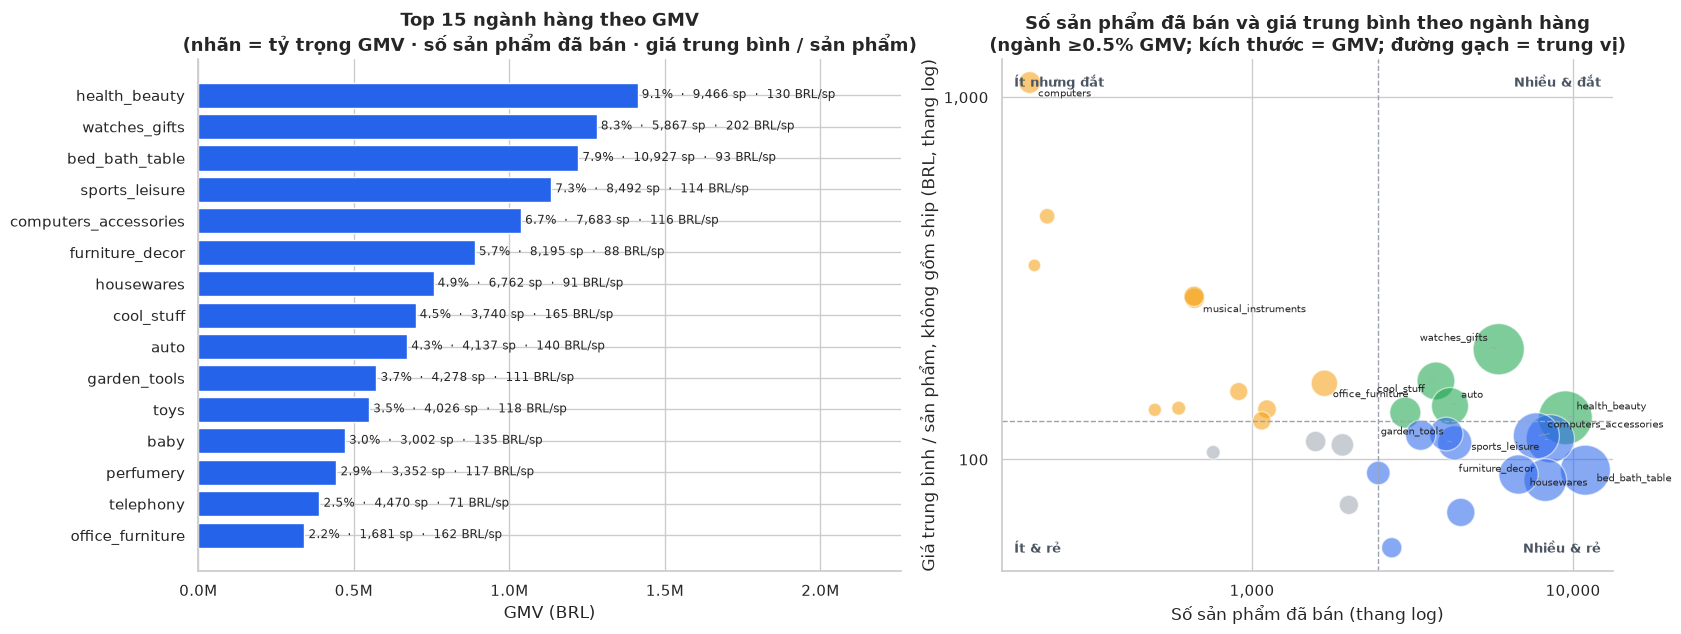

Tổng 74 ngành. Top 5 = 39.2%, top 10 = 62.3%, số ngành đạt 80% GMV = 18
Trung vị (ngành ≥0.5% GMV): 2,473 sản phẩm, giá TB R$ 128
               n  gmv_share                                                                examples
group                                                                                              
Nhiều & rẻ    11   0.481080  bed_bath_table, sports_leisure, computers_accessories, furniture_decor
Nhiều & đắt    5   0.292119                          health_beauty, watches_gifts, cool_stuff, auto
Ít & rẻ        4   0.046890            pet_shop, unknown, fashion_bags_accessories, home_appliances
Ít nhưng đắt  11   0.119509      office_furniture, computers, musical_instruments, small_appliances
      category  units  avg_price
 watches_gifts   5867      201.6
bed_bath_table  10927       93.4
     computers    203     1098.3


In [5]:
categories = q("""SELECT category, sum(gmv) AS gmv, sum(price) AS product_rev, count(*) AS units,
                         count(DISTINCT product_id) AS skus, count(DISTINCT seller_key) AS sellers, avg(price) AS avg_price
                  FROM item_ps GROUP BY 1 ORDER BY gmv DESC""")
categories["share"] = categories.gmv / categories.gmv.sum()
categories["cum_share"] = categories.share.cumsum()

TOP_BAR_N = 15
top_categories = categories.head(TOP_BAR_N).iloc[::-1]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(17, 6.5), gridspec_kw={"width_ratios": [1.15, 1]})
category_bars = ax1.barh(top_categories.category, top_categories.gmv, color=C_MAIN)
ax1.bar_label(category_bars, labels=[f"{s:.1%}  ·  {u:,} sp  ·  {p:,.0f} BRL/sp"
                                     for s, u, p in zip(top_categories.share, top_categories.units, top_categories.avg_price)],
              padding=3, fontsize=8.5)
brl_axis(ax1, "x"); ax1.set_xlim(0, top_categories.gmv.max() * 1.6)
ax1.set_title(f"Top {TOP_BAR_N} ngành hàng theo GMV\n(nhãn = tỷ trọng GMV · số sản phẩm đã bán · giá trung bình / sản phẩm)")
ax1.set_xlabel("GMV (BRL)")

# Bản đồ "số lượng × giá": chỉ ngành đủ lớn
VOLUME_PRICE_NAMES = ("Nhiều & đắt", "Nhiều & rẻ", "Ít nhưng đắt", "Ít & rẻ")
VOLUME_PRICE_COLORS = dict(zip(VOLUME_PRICE_NAMES, [C_GOOD, C_MAIN, C_ACCENT, C_GREY]))
major = categories[categories.share >= MIN_CATEGORY_SHARE].copy()
median_units, median_price = major.units.median(), major.avg_price.median()
major["group"] = quadrant(major.units >= median_units, major.avg_price >= median_price, VOLUME_PRICE_NAMES)
ax2.scatter(major.units, major.avg_price, s=major.gmv / major.gmv.max() * 1500, alpha=0.55,
            c=major.group.map(VOLUME_PRICE_COLORS), edgecolor="white")
ax2.axvline(median_units, color=C_GREY, ls="--", lw=1); ax2.axhline(median_price, color=C_GREY, ls="--", lw=1)
ax2.set_xscale("log"); ax2.set_yscale("log")
ax2.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax2.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:,.0f}"))
for j, (_, r) in enumerate(major.nlargest(10, "gmv").iterrows()):
    ax2.annotate(r.category, (r.units, r.avg_price), fontsize=7.5, ha="right" if j % 2 else "left",
                 xytext=(-8 if j % 2 else 8, 6 if j % 4 < 2 else -8), textcoords="offset points",
                 arrowprops=dict(arrowstyle="-", color=C_GREY, lw=0.5))
for _, r in major[major.group == "Ít nhưng đắt"].nlargest(3, "gmv").iterrows():
    ax2.annotate(r.category, (r.units, r.avg_price), fontsize=7.5, xytext=(6, -10), textcoords="offset points")
for (x, y, name) in [(0.98, 0.97, "Nhiều & đắt"), (0.02, 0.97, "Ít nhưng đắt"), (0.98, 0.03, "Nhiều & rẻ"), (0.02, 0.03, "Ít & rẻ")]:
    ax2.text(x, y, name, transform=ax2.transAxes, ha="right" if x > 0.5 else "left", va="top" if y > 0.5 else "bottom",
             fontsize=9, color=C_MUTED_TEXT, fontweight="bold")
ax2.set_xlabel("Số sản phẩm đã bán (thang log)"); ax2.set_ylabel("Giá trung bình / sản phẩm, không gồm ship (BRL, thang log)")
ax2.set_title(f"Số sản phẩm đã bán và giá trung bình theo ngành hàng\n(ngành ≥{MIN_CATEGORY_SHARE:.1%} GMV; kích thước = GMV; đường gạch = trung vị)")
plt.tight_layout(); plt.show()

print(f"Tổng {len(categories)} ngành. Top 5 = {categories.share.head(5).sum():.1%}, top 10 = {categories.share.head(10).sum():.1%}, "
      f"số ngành đạt 80% GMV = {(categories.cum_share < 0.8).sum() + 1}")
print(f"Trung vị (ngành ≥{MIN_CATEGORY_SHARE:.1%} GMV): {median_units:,.0f} sản phẩm, giá TB R$ {median_price:,.0f}")
print(major.groupby("group").agg(n=("category", "size"), gmv_share=("share", "sum"),
                                 examples=("category", lambda s: ", ".join(s.head(4)))).to_string())
print(major.loc[major.category.isin(["computers", "watches_gifts", "bed_bath_table"]), ["category", "units", "avg_price"]].round(1).to_string(index=False))

> **🔎 Kết quả chính**
> - Doanh thu tập trung vừa phải: top 5 ngành = **39,2%**, top 10 = **62,3%**, cần **18 ngành** để đạt 80% GMV.
>   Dẫn đầu: health_beauty 9,1%, watches_gifts 8,3%, bed_bath_table 7,9%, sports_leisure 7,3%, computers_accessories 6,7%.
> - Đặt số lượng cạnh giá cho thấy **4 nhóm ngành với đòn bẩy khác nhau** (30 ngành ≥0,5% GMV, chia theo trung vị 2.630 sản phẩm và R$ 123 / đơn vị):
>   - **Nhiều & rẻ** (10 ngành, **46% GMV**): bed_bath_table (11.097 đv, R$ 93), furniture_decor, housewares, sports_leisure, computers_accessories.
>     Đòn bẩy = **số lượng** (combo, giảm phí ship, khuyến mãi theo giỏ).
>   - **Nhiều & đắt** (5 ngành, **29% GMV**): health_beauty, **watches_gifts (R$ 201 / đv)**, cool_stuff, auto. Đây là nhóm "vàng", cần bảo vệ nguồn cung.
>   - **Ít nhưng đắt** (10 ngành, 11% GMV): computers (**R$ 1.098 / đv**), office_furniture, musical_instruments, small_appliances. Đòn bẩy = **trả góp, trải nghiệm**.
>   - **Ít & rẻ** (5 ngành, 6% GMV): stationery, pet_shop, fashion_bags_accessories… Ưu tiên thấp.
> - *Lưu ý:* trục giá dùng `price` (không gồm phí ship), nên phân tách này áp dụng cho **doanh thu hàng**, không cho GMV.

## 3. Ma trận tăng trưởng ngành hàng
*Câu hỏi: "Ngành nào là trụ cột, ngành nào đang lên, ngành nào đang tụt lại?"*

Ma trận kiểu BCG cho các ngành có ≥ 0,5% GMV trong kỳ này (và có doanh thu trong cùng kỳ năm trước):
- **Trục X** = tỷ trọng GMV kỳ này (quy mô hiện tại). **Trục Y** = tăng trưởng GMV kỳ này so với cùng kỳ năm trước.
- **Đường ngang** = tăng trưởng của toàn sàn: ngành nằm trên đường này đang **giành thêm tỷ trọng**, nằm dưới là **mất tỷ trọng**.

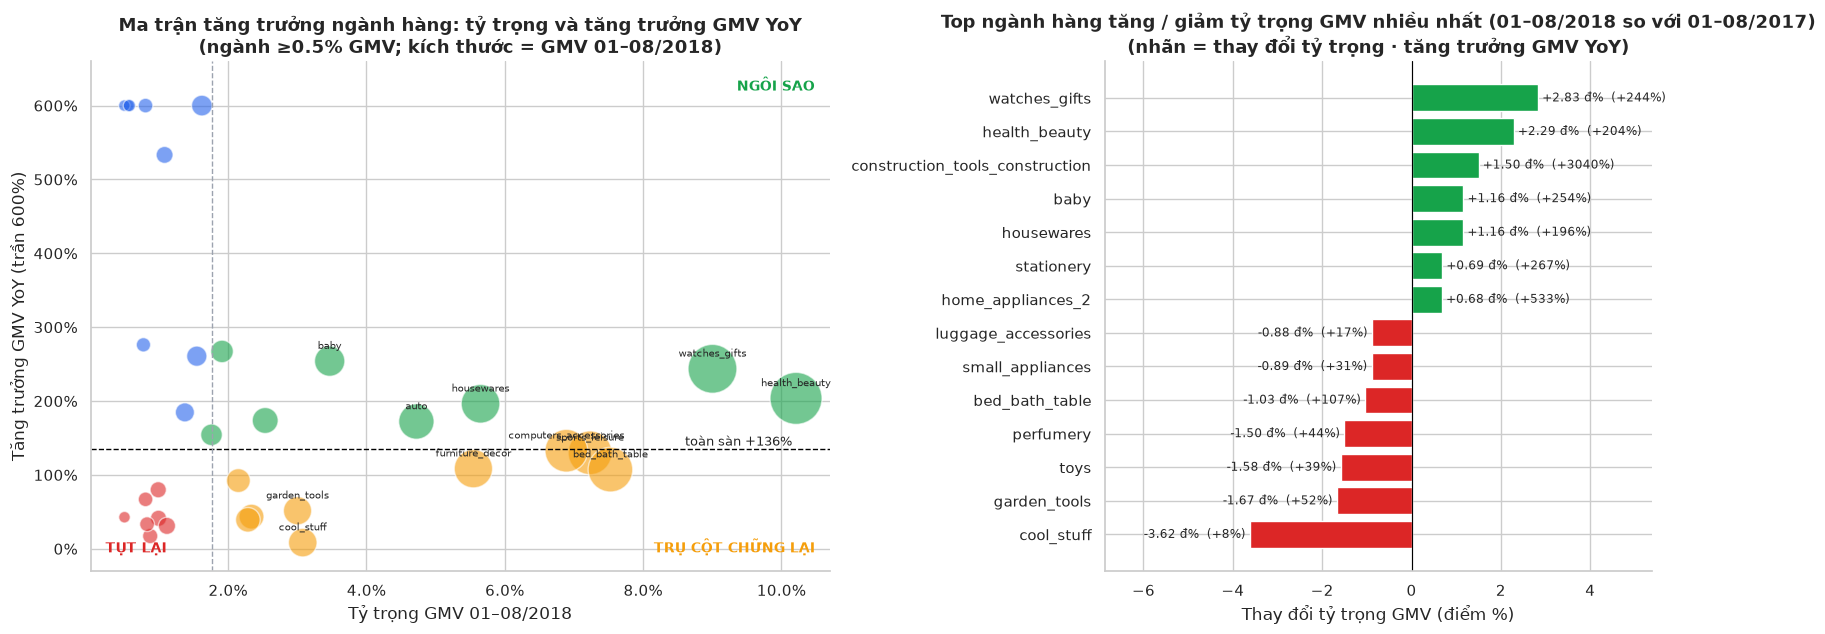

Ngưỡng tỷ trọng (trung vị): 1.76%
Ngành vượt trần:                              category  gmv_prev   gmv_cur  growth
      construction_tools_construction   4339.31 136272.93   30.40
                    home_construction   7318.21  67837.10    8.27
           agro_industry_and_commerce   5159.41  46787.96    8.07
            construction_tools_lights   1072.43  42099.97   38.26
small_appliances_home_oven_and_coffee    222.51  48173.34  215.50
                   n  share_cur                                                                                                                categories
quadrant                                                                                                                                                 
Ngôi sao           8   0.392750                                                           health_beauty, watches_gifts, housewares, auto, baby, telephony
Trụ cột chững lại  9   0.400666                          bed_bath_table, sports_leisure, co

In [6]:
category_growth = q(f"""SELECT category, sum(gmv) FILTER (WHERE {P.prev}) AS gmv_prev, sum(gmv) FILTER (WHERE {P.cur}) AS gmv_cur
                        FROM item_ps GROUP BY 1""").fillna(0)
category_growth["share_cur"] = category_growth.gmv_cur / category_growth.gmv_cur.sum()
category_growth["share_prev"] = category_growth.gmv_prev / category_growth.gmv_prev.sum()
category_growth["growth"] = category_growth.gmv_cur / category_growth.gmv_prev.replace(0, np.nan) - 1
category_growth["share_change_pp"] = (category_growth.share_cur - category_growth.share_prev) * 100
matrix = category_growth[(category_growth.share_cur >= MIN_CATEGORY_SHARE) & (category_growth.gmv_prev > 0)].copy()
share_cut = matrix.share_cur.median()
GROWTH_NAMES = ("Ngôi sao", "Trụ cột chững lại", "Đang lên", "Tụt lại")
GROWTH_COLORS = dict(zip(GROWTH_NAMES, [C_GOOD, C_ACCENT, C_MAIN, C_BAD]))
matrix["quadrant"] = quadrant(matrix.share_cur >= share_cut, matrix.growth >= MARKET_GROWTH, GROWTH_NAMES)
matrix["y"] = matrix.growth.clip(upper=GROWTH_AXIS_CAP)
capped = matrix[matrix.growth > GROWTH_AXIS_CAP]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(17, 6.5), gridspec_kw={"width_ratios": [1.35, 1]})
ax1.scatter(matrix.share_cur, matrix.y, s=matrix.gmv_cur / matrix.gmv_cur.max() * 1400, c=matrix.quadrant.map(GROWTH_COLORS),
            alpha=0.6, edgecolor="white")
ax1.axhline(MARKET_GROWTH, color="black", ls="--", lw=1)
ax1.text(matrix.share_cur.max(), MARKET_GROWTH, f"toàn sàn {MARKET_GROWTH:+.0%} ", ha="right", va="bottom", fontsize=9)
ax1.axvline(share_cut, color=C_GREY, ls="--", lw=1)
for _, r in matrix[(matrix.share_cur >= 0.03) & (matrix.growth <= GROWTH_AXIS_CAP)].iterrows():
    ax1.annotate(r.category, (r.share_cur, r.y), fontsize=7.5, ha="center", va="bottom", xytext=(0, 7), textcoords="offset points")
ax1.set_ylim(-0.3, GROWTH_AXIS_CAP + 0.6)
pct_axis(ax1, "x"); pct_axis(ax1)
ax1.set_xlabel(f"Tỷ trọng GMV {P.label_cur}"); ax1.set_ylabel(f"Tăng trưởng GMV YoY (trần {GROWTH_AXIS_CAP:.0%})")
for (x, y, name) in [(0.98, 0.97, "Ngôi sao"), (0.98, 0.03, "Trụ cột chững lại"), (0.02, 0.03, "Tụt lại")]:
    ax1.text(x, y, name.upper(), transform=ax1.transAxes, ha="right" if x > 0.5 else "left", va="top" if y > 0.5 else "bottom",
             fontsize=10, color=GROWTH_COLORS[name], fontweight="bold")
ax1.set_title(f"Ma trận tăng trưởng ngành hàng: tỷ trọng và tăng trưởng GMV YoY\n(ngành ≥{MIN_CATEGORY_SHARE:.1%} GMV; kích thước = GMV {P.label_cur})")

share_movers = pd.concat([matrix.nlargest(7, "share_change_pp"), matrix.nsmallest(7, "share_change_pp")]).sort_values("share_change_pp")
mover_bars = ax2.barh(share_movers.category, share_movers.share_change_pp, color=np.where(share_movers.share_change_pp > 0, C_GOOD, C_BAD))
ax2.bar_label(mover_bars, labels=[f"{v:+.2f} đ%  ({g:+.0%})" for v, g in zip(share_movers.share_change_pp, share_movers.growth)],
              padding=3, fontsize=8.5)
ax2.axvline(0, color="black", lw=0.8); ax2.set_xlim(share_movers.share_change_pp.min() * 1.9, share_movers.share_change_pp.max() * 1.9)
ax2.set_xlabel("Thay đổi tỷ trọng GMV (điểm %)")
ax2.set_title(f"Top ngành hàng tăng / giảm tỷ trọng GMV nhiều nhất ({P.label_cur} so với {P.label_prev})\n(nhãn = thay đổi tỷ trọng · tăng trưởng GMV YoY)")
plt.tight_layout(); plt.show()

print(f"Ngưỡng tỷ trọng (trung vị): {share_cut:.2%}")
print("Ngành vượt trần:", capped[["category", "gmv_prev", "gmv_cur", "growth"]].round(2).to_string(index=False))
print(matrix.groupby("quadrant").agg(n=("category", "size"), share_cur=("share_cur", "sum"),
      categories=("category", lambda s: ", ".join(matrix.loc[s.index].sort_values("share_cur", ascending=False).category.head(6)))).to_string())
slower = matrix.growth < MARKET_GROWTH
print(f"\nTỷ trọng GMV {P.label_cur} của các ngành (≥{MIN_CATEGORY_SHARE:.1%}) tăng chậm hơn sàn: {matrix.share_cur[slower].sum():.1%} "
      f"({slower.sum()} ngành); riêng nhóm Trụ cột chững lại: {matrix.share_cur[matrix.quadrant == 'Trụ cột chững lại'].sum():.1%}")

> **🔎 Kết quả chính**
> - Toàn sàn tăng **+140%**. Chia theo ma trận (ngưỡng quy mô = trung vị 1,9% GMV):
>   - **Ngôi sao** (7 ngành, **37,5% GMV 2018**): health_beauty (+212%), watches_gifts (+250%), housewares (+203%), baby (+262%), auto, telephony; đang giành thêm tỷ trọng (watches_gifts +2,81 điểm %, health_beauty +2,36 điểm %).
>   - **Trụ cột chững lại** (9 ngành, **40,0% GMV**): bed_bath_table (+113%), sports_leisure, computers_accessories, furniture_decor, garden_tools (+55%); đáng lo nhất **cool_stuff chỉ +10%** (mất 3,62 điểm % tỷ trọng).
>   - **Đang lên** (9 ngành, 10,1% GMV): construction_tools_construction (4,3K → 141K BRL), home_construction, agro_industry_and_commerce, small_appliances_home_oven_and_coffee tăng hàng chục lần **từ nền gần bằng 0**; pet_shop, electronics, musical_instruments tăng ổn định hơn.
>   - **Tụt lại** (6 ngành, 5,6% GMV): computers, small_appliances, luggage_accessories, consoles_games, fashion_bags_accessories.
> - **15 ngành chiếm 45,6% GMV 2018 đang tăng chậm hơn sàn**; cool_stuff, toys, garden_tools, perfumery chỉ +10% đến +55%.

## 4. Cơ cấu ngành hàng theo tháng
*Câu hỏi: "Tỷ trọng các ngành lớn có ổn định không? Ngành nào có nhịp riêng?"*

Lấy 8 ngành có GMV lớn nhất trong cửa sổ xu hướng (hiện là 01/2017–08/2018), các ngành còn lại gom thành *Khác*.
Heatmap dùng **chỉ số tỷ trọng** = tỷ trọng của ngành trong tháng / tỷ trọng TB của chính ngành đó, để loại bỏ đà tăng chung của sàn.

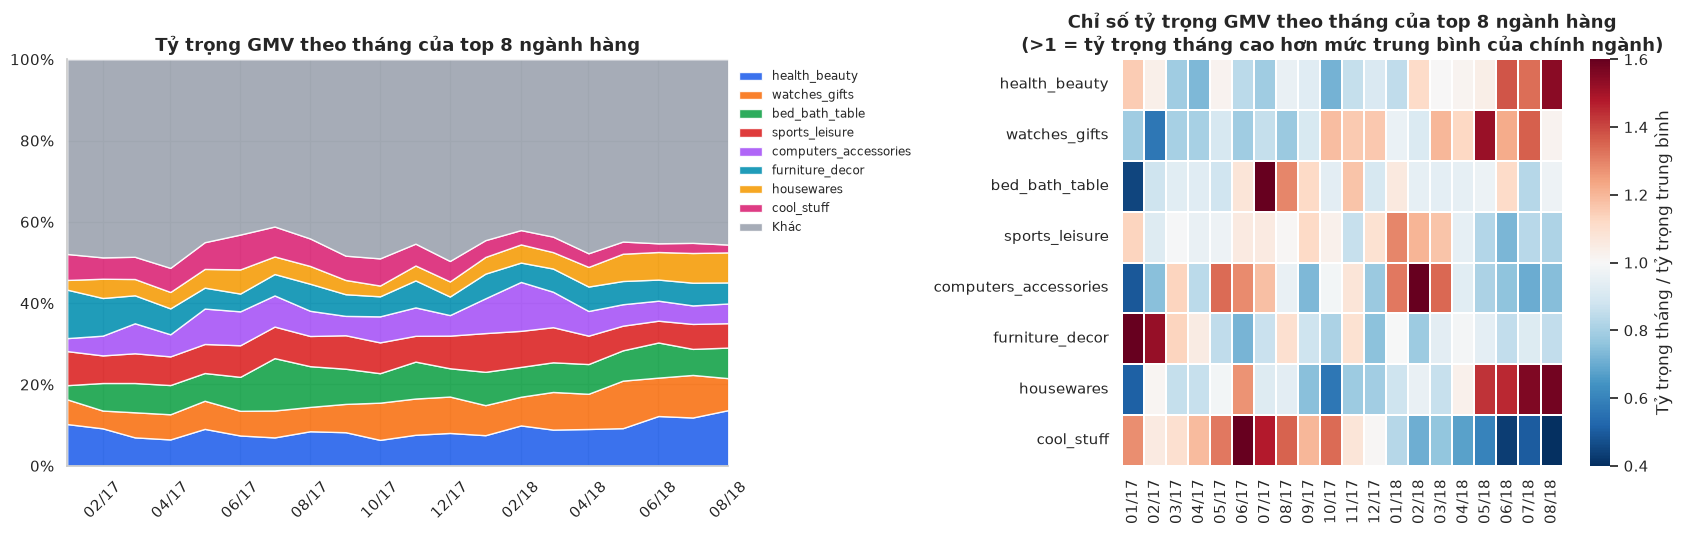

Tỷ trọng TB 01/2017–08/2018 vs tháng GMV cao nhất 11/2017:
                          TB  11/2017  chênh (đ%)
group                                            
health_beauty          0.089    0.076      -1.259
watches_gifts          0.077    0.089       1.205
bed_bath_table         0.077    0.091       1.336
sports_leisure         0.074    0.063      -1.021
computers_accessories  0.065    0.070       0.488
furniture_decor        0.061    0.066       0.562
housewares             0.047    0.037      -1.009
cool_stuff             0.050    0.054       0.381
Khác                   0.460    0.454      -0.682

Tháng có chỉ số tỷ trọng cao nhất / thấp nhất của từng ngành:
                        đỉnh  giá trị đỉnh    đáy  giá trị đáy
group                                                         
health_beauty          08/18          1.54  10/17         0.72
watches_gifts          05/18          1.52  02/17         0.57
bed_bath_table         07/17          1.66  01/17         0.45
sports_leisur

In [7]:
monthly_category = q(f"""SELECT purchase_month AS month, category, sum(gmv) AS gmv FROM item_ps
                         WHERE {P.in_period} GROUP BY 1, 2""")
monthly_category["month"] = pd.to_datetime(monthly_category.month)
top_mix_categories = monthly_category.groupby("category").gmv.sum().nlargest(TOP_CATEGORY_N).index.tolist()
monthly_category["group"] = np.where(monthly_category.category.isin(top_mix_categories), monthly_category.category, "Khác")
monthly_gmv = (monthly_category.pivot_table(index="month", columns="group", values="gmv", aggfunc="sum")
               .fillna(0)[top_mix_categories + ["Khác"]])
monthly_share = monthly_gmv.div(monthly_gmv.sum(axis=1), axis=0)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(17, 5.5), gridspec_kw={"width_ratios": [1.2, 1]})
ax1.stackplot(monthly_share.index, monthly_share.T.values, labels=monthly_share.columns,
              colors=CATEGORY_COLORS[:TOP_CATEGORY_N] + [C_GREY], alpha=0.9)
pct_axis(ax1); ax1.set_ylim(0, 1); month_axis(ax1); ax1.set_xlim(monthly_share.index[0], monthly_share.index[-1])
ax1.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0), fontsize=8.5, frameon=False)
ax1.set_title(f"Tỷ trọng GMV theo tháng của top {TOP_CATEGORY_N} ngành hàng")

share_index = (monthly_share[top_mix_categories] / monthly_share[top_mix_categories].mean()).T
share_index.columns = [d.strftime("%m/%y") for d in share_index.columns]
sns.heatmap(share_index, ax=ax2, cmap="RdBu_r", center=1, vmin=0.4, vmax=1.6, cbar_kws={"label": "Tỷ trọng tháng / tỷ trọng trung bình"},
            linewidths=0.3, linecolor="white")
ax2.set_xlabel(""); ax2.set_ylabel("")
ax2.set_title(f"Chỉ số tỷ trọng GMV theo tháng của top {TOP_CATEGORY_N} ngành hàng\n(>1 = tỷ trọng tháng cao hơn mức trung bình của chính ngành)")
plt.tight_layout(); plt.show()

# Tháng GMV cao nhất của sàn (với dữ liệu hiện tại là 11/2017 – Black Friday) có làm đổi cơ cấu ngành không?
avg_share = monthly_share.mean()
peak_month = monthly_gmv.sum(axis=1).idxmax(); peak_share = monthly_share.loc[peak_month]
print(f"Tỷ trọng TB {P.label_trend} vs tháng GMV cao nhất {peak_month:%m/%Y}:")
print(pd.DataFrame({"TB": avg_share, f"{peak_month:%m/%Y}": peak_share, "chênh (đ%)": (peak_share - avg_share) * 100}).round(3).to_string())
print("\nTháng có chỉ số tỷ trọng cao nhất / thấp nhất của từng ngành:")
print(pd.DataFrame({"đỉnh": share_index.idxmax(axis=1), "giá trị đỉnh": share_index.max(axis=1).round(2),
                    "đáy": share_index.idxmin(axis=1), "giá trị đáy": share_index.min(axis=1).round(2)}).to_string())
first_6m, last_6m = monthly_share.iloc[:6].mean(), monthly_share.iloc[-6:].mean()
first_label = f"{monthly_share.index[0]:%m/%Y}–{monthly_share.index[5]:%m/%Y}"
last_label = f"{monthly_share.index[-6]:%m/%Y}–{monthly_share.index[-1]:%m/%Y}"
print(f"\nTỷ trọng TB 6 tháng đầu ({first_label}) vs 6 tháng cuối ({last_label}):")
print(pd.DataFrame({"đầu": first_6m, "cuối": last_6m, "chênh (đ%)": (last_6m - first_6m) * 100}).round(3).sort_values("chênh (đ%)").to_string())

> **🔎 Kết quả chính**
> - **Cơ cấu thay đổi theo xu hướng nhiều hơn theo mùa vụ.** So 01–06/2017 với 03–08/2018: watches_gifts 6,0% → **9,5%**, health_beauty 8,2% → **10,9%**, housewares 4,3% → 6,2%;
>   ngược lại **cool_stuff 6,4% → 2,8%**, furniture_decor 7,4% → 5,5%.
> - **Black Friday 11/2017 không làm đổi cơ cấu**: các ngành lớn chỉ lệch ±1,3 điểm %; Black Friday làm **cả sàn tăng**, không riêng ngành nào.
> - **computers_accessories** và **sports_leisure** mạnh bất thường trong **01–03/2018** (computers_accessories 02/2018 gấp 1,84 lần tỷ trọng TB).

## 5. Phân khúc giá sản phẩm
*Câu hỏi: "Doanh thu đến từ hàng rẻ hay hàng đắt? Phí ship chiếm bao nhiêu ở mỗi tầng giá?"*

Chia **giá bán 1 đơn vị** (`price`) thành 6 tầng. Lưu ý: đây là tầng giá **của sản phẩm**, khác với tầng **giá trị đơn hàng**
(`Order Value Band`) ở `customer_behaviour` §5. So sánh tỷ trọng **số sản phẩm đã bán** với tỷ trọng **GMV**, và **phí ship / GMV** trong từng tầng.

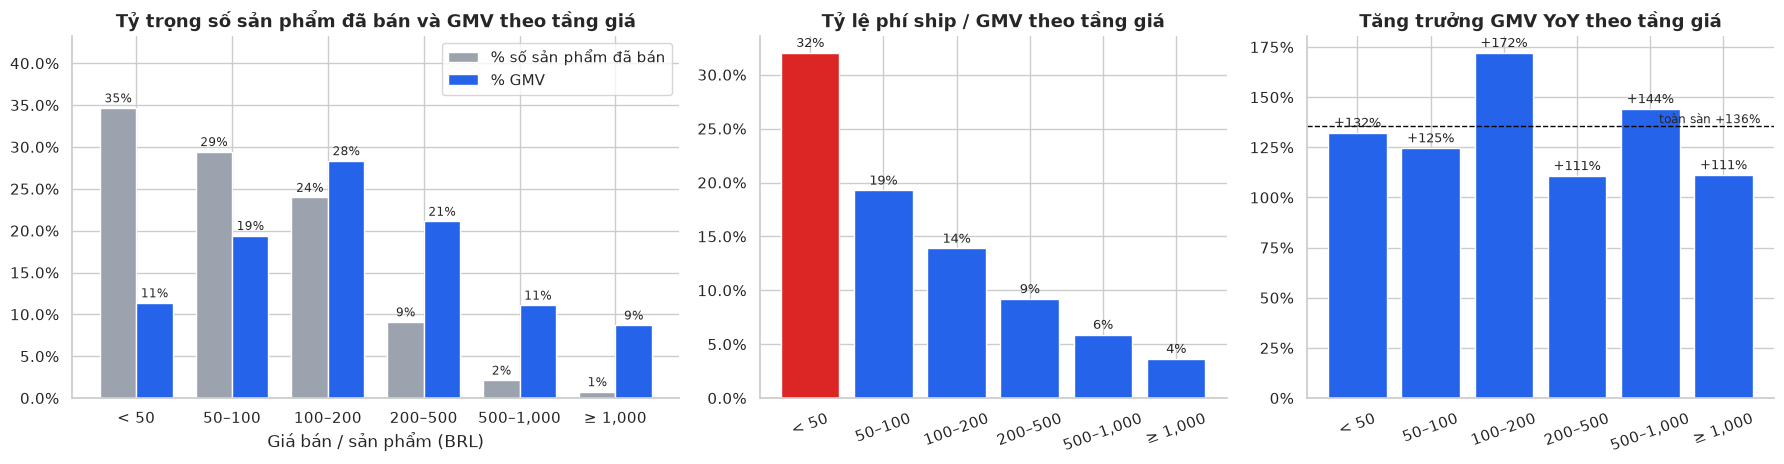

     band  units  unit_share        gmv  gmv_share  freight_share  growth  skus  sellers
     < 50  38288       0.346 1763877.55      0.114          0.320   1.323 11277     1708
   50–100  32521       0.294 3012867.34      0.194          0.193   1.246  8881     1705
  100–200  26478       0.240 4400519.42      0.283          0.139   1.721  7792     1603
  200–500  10043       0.091 3276681.57      0.211          0.092   1.108  3984     1107
500–1,000   2348       0.021 1721224.28      0.111          0.059   1.442  1078      416
  ≥ 1,000    822       0.007 1350836.25      0.087          0.037   1.112   445      197

Giá trung vị / đơn vị: R$ 75.0; giá TB: R$ 120.5


In [8]:
price_band_sql = "CASE " + " ".join(f"WHEN price < {hi} THEN {i}" for i, hi in enumerate(PRICE_EDGES[1:-1])) + f" ELSE {len(PRICE_EDGES) - 2} END"
price_bands = q(f"""SELECT {price_band_sql} AS band, count(*) AS units, sum(gmv) AS gmv, sum(freight_value) AS freight,
                           count(DISTINCT seller_key) AS sellers, count(DISTINCT product_id) AS skus,
                           sum(gmv) FILTER (WHERE {P.prev}) AS gmv_prev, sum(gmv) FILTER (WHERE {P.cur}) AS gmv_cur
                    FROM item_ps GROUP BY 1 ORDER BY 1""")
price_bands["band"] = [PRICE_LABELS[i] for i in price_bands.band]
price_bands["unit_share"] = price_bands.units / price_bands.units.sum()
price_bands["gmv_share"] = price_bands.gmv / price_bands.gmv.sum()
price_bands["freight_share"] = price_bands.freight / price_bands.gmv
price_bands["growth"] = price_bands.gmv_cur / price_bands.gmv_prev - 1

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 4.8), gridspec_kw={"width_ratios": [1.3, 1, 1]})
share_bars(ax1, price_bands.band, price_bands.unit_share, price_bands.gmv_share, "% số sản phẩm đã bán")
ax1.set_xlabel("Giá bán / sản phẩm (BRL)"); ax1.set_title("Tỷ trọng số sản phẩm đã bán và GMV theo tầng giá")

x = np.arange(len(price_bands))
freight_bars = ax2.bar(x, price_bands.freight_share, color=[C_BAD if v > 0.2 else C_MAIN for v in price_bands.freight_share])
ax2.bar_label(freight_bars, labels=[f"{v:.0%}" for v in price_bands.freight_share], fontsize=9, padding=2)
ax2.set_xticks(x, price_bands.band, rotation=20); pct_axis(ax2); ax2.set_title("Tỷ lệ phí ship / GMV theo tầng giá")

growth_bars = ax3.bar(x, price_bands.growth, color=C_MAIN)
ax3.bar_label(growth_bars, labels=[f"{v:+.0%}" for v in price_bands.growth], fontsize=9, padding=2)
ax3.axhline(MARKET_GROWTH, color="black", ls="--", lw=1)
ax3.text(len(price_bands) - 0.5, MARKET_GROWTH, f"toàn sàn {MARKET_GROWTH:+.0%}", ha="right", va="bottom", fontsize=8.5)
ax3.set_xticks(x, price_bands.band, rotation=20); pct_axis(ax3); ax3.set_title("Tăng trưởng GMV YoY theo tầng giá")
plt.tight_layout(); plt.show()

print(price_bands[["band", "units", "unit_share", "gmv", "gmv_share", "freight_share", "growth", "skus", "sellers"]].round(3).to_string(index=False))
unit_price_median = q(f"SELECT {median_sql('price')} AS m FROM item_ps").m[0]
print(f"\nGiá trung vị / đơn vị: R$ {unit_price_median:.1f}; "
      f"giá TB: R$ {q('SELECT avg(price) AS m FROM item_ps').m[0]:.1f}")

> **🔎 Kết quả chính**
> - Giá trung vị chỉ **R$ 74,9 / đơn vị** (TB R$ 120,4): sàn chủ yếu bán **hàng giá thấp**.
> - Số lượng và doanh thu lệch nhau mạnh: hàng **< 100 BRL = 64% số sản phẩm nhưng chỉ 31% GMV**; hàng **≥ 200 BRL = 12% số sản phẩm nhưng 41% GMV**. Tầng **100–200 BRL** đóng góp GMV lớn nhất (**28%**).
> - **Phí ship chiếm 32% GMV ở tầng < 50 BRL** và 19% ở tầng 50–100, so với 4–6% ở hàng ≥ 500 BRL: với hàng rẻ, khách trả gần 1 đồng ship cho mỗi 2 đồng hàng.
> - Tăng trưởng nghiêng về **tầng giữa**: 100–200 BRL **+178%**, 500–1.000 BRL +149%, vượt sàn; các tầng còn lại +115% đến +136%.

## 6. Danh mục sản phẩm & đuôi dài
*Câu hỏi: "Doanh thu dựa vào vài sản phẩm 'hit' hay vào hàng chục nghìn sản phẩm bán lẻ tẻ?"*

Phân nhóm SKU theo **tổng số sản phẩm đã bán** trong toàn kỳ và đo đóng góp GMV của từng nhóm.

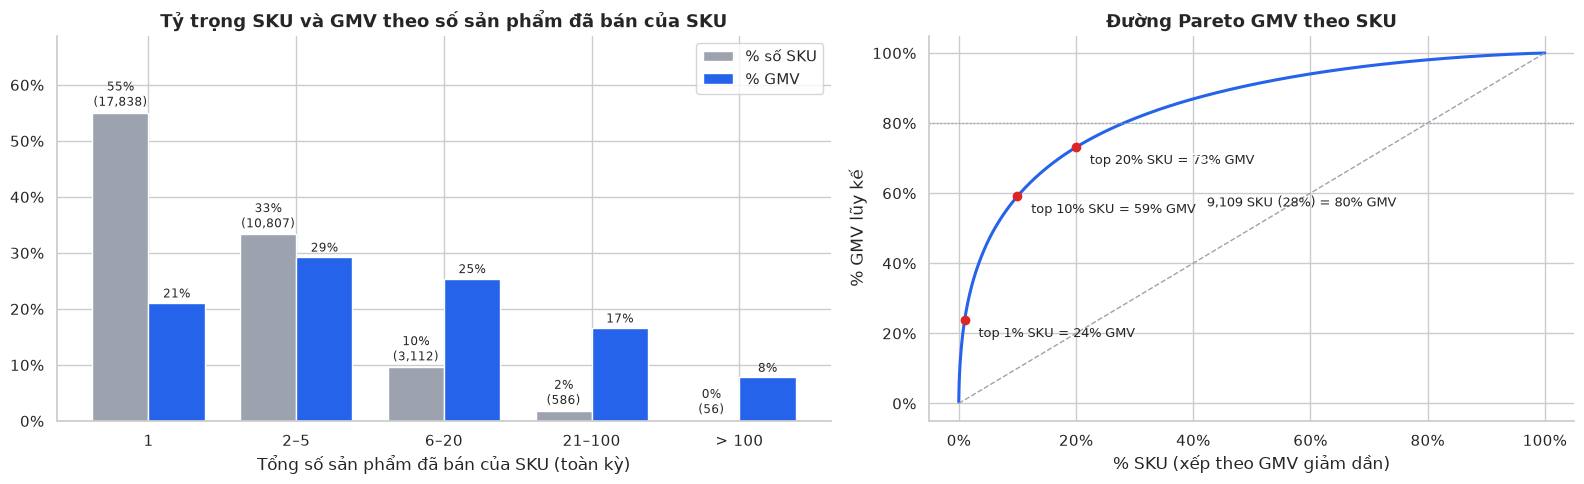

            skus         gmv  sku_share  gmv_share
unit_band                                         
1          17838  3267184.51      0.551      0.210
2–5        10807  4538722.02      0.334      0.292
6–20        3112  3942328.97      0.096      0.254
21–100       586  2572460.60      0.018      0.166
> 100         56  1205310.31      0.002      0.078

32,399 SKU; trung vị 1 sản phẩm / SKU; SKU bán ≥ 2 sản phẩm: 44.9% số SKU; top 1 SKU = 0.43% GMV; top 100 SKU = 13.3% GMV; 9,109 SKU (28.1%) = 80% GMV
SKU do ≥2 người bán cùng bán: 3.7% số SKU, 13.2% GMV


In [9]:
skus = q("""SELECT product_id, arbitrary(category) AS category, count(*) AS units, sum(gmv) AS gmv,
                   count(DISTINCT seller_key) AS sellers, avg(price) AS avg_price
            FROM item_ps GROUP BY 1 ORDER BY gmv DESC""")
skus["cum_share"] = skus.gmv.cumsum() / skus.gmv.sum()
skus["pct_skus"] = np.arange(1, len(skus) + 1) / len(skus)
skus["unit_band"] = pd.cut(skus.units, SKU_UNIT_EDGES, labels=SKU_UNIT_LABELS)
sku_bands = skus.groupby("unit_band", observed=False).agg(skus=("product_id", "size"), gmv=("gmv", "sum"))
sku_bands["sku_share"] = sku_bands.skus / sku_bands.skus.sum(); sku_bands["gmv_share"] = sku_bands.gmv / sku_bands.gmv.sum()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw={"width_ratios": [1.2, 1]})
share_bars(ax1, sku_bands.index, sku_bands.sku_share, sku_bands.gmv_share, "% số SKU",
           left_text=[f"{v:.0%}\n({n:,})" for v, n in zip(sku_bands.sku_share, sku_bands.skus)])
ax1.set_xlabel("Tổng số sản phẩm đã bán của SKU (toàn kỳ)")
ax1.set_title("Tỷ trọng SKU và GMV theo số sản phẩm đã bán của SKU")

ax2.plot(skus.pct_skus, skus.cum_share, color=C_MAIN, lw=2.2); ax2.plot([0, 1], [0, 1], color=C_GREY, ls="--", lw=1)
for top_pct in (0.01, 0.1, 0.2):
    v = skus.cum_share.iloc[int(len(skus) * top_pct) - 1]
    ax2.scatter([top_pct], [v], color=C_BAD, zorder=3)
    ax2.annotate(f"top {top_pct:.0%} SKU = {v:.0%} GMV", (top_pct, v), xytext=(10, -12), textcoords="offset points", fontsize=9)
n_skus_80 = (skus.cum_share < 0.8).sum() + 1
ax2.axhline(0.8, color=C_GREY, ls=":", lw=1)
ax2.annotate(f"{n_skus_80:,} SKU ({n_skus_80 / len(skus):.0%}) = 80% GMV", (n_skus_80 / len(skus), 0.8), xytext=(60, -60),
             textcoords="offset points", fontsize=9, arrowprops=dict(arrowstyle="->"))
pct_axis(ax2); pct_axis(ax2, "x"); ax2.set_xlabel("% SKU (xếp theo GMV giảm dần)"); ax2.set_ylabel("% GMV lũy kế")
ax2.set_title("Đường Pareto GMV theo SKU")
plt.tight_layout(); plt.show()

print(sku_bands.round(3).to_string())
print(f"\n{len(skus):,} SKU; trung vị {skus.units.median():.0f} sản phẩm / SKU; SKU bán ≥ 2 sản phẩm: {(skus.units >= 2).mean():.1%} số SKU; "
      f"top 1 SKU = {skus.gmv.iloc[0] / skus.gmv.sum():.2%} GMV; top 100 SKU = {skus.gmv.head(100).sum() / skus.gmv.sum():.1%} GMV; "
      f"{n_skus_80:,} SKU ({n_skus_80 / len(skus):.1%}) = 80% GMV")
multi_seller = skus.sellers >= 2
print(f"SKU do ≥2 người bán cùng bán: {multi_seller.mean():.1%} số SKU, {skus.gmv[multi_seller].sum() / skus.gmv.sum():.1%} GMV")

> **🔎 Kết quả chính**
> - Olist là sàn **đuôi dài điển hình**: 32.729 SKU, **trung vị chỉ 1 sản phẩm đã bán / SKU**. 55% SKU (17.983) chỉ bán đúng 1 lần nhưng vẫn tạo **21% GMV**; SKU bán ≤ 5 sản phẩm tạo **50% GMV**.
> - **Không có sản phẩm "hit"**: SKU lớn nhất chỉ chiếm 0,43% GMV, top 100 SKU = 13,2%. Cần **9.191 SKU (28%)** để đạt 80% GMV, Pareto thoải hơn nhiều so với người bán (18% người bán = 80% GMV).
> - Chỉ 57 SKU bán > 100 sản phẩm (7,8% GMV); chỉ **45,1%** SKU bán được từ 2 sản phẩm trở lên.
> - Gần như mọi SKU chỉ có 1 người bán: SKU có ≥ 2 người bán chỉ chiếm 3,7% SKU (13,2% GMV), nên **cạnh tranh giá trên cùng sản phẩm rất ít**.
> - Sức mạnh doanh thu nằm ở **độ rộng danh mục**, không ở vài sản phẩm chủ lực.

In [10]:
con.close()